# Notebook setup: games per season (step 0.34)

The team situation analysis explores the marts in notebooks. Every notebook reads them through `pipeline/analysis.py`:

- `read_mart(name, where, params)` runs `SELECT * FROM marts.<name>` into a pandas DataFrame, with any filter values passed as bound parameters.
- `regular_season(df)` keeps finished regular-season games from 1999 to 2025, the range every effect estimate uses (`docs/decisions.md`, "Analysis rules, set before any effect is estimated").
- `chart_style()` and `save_figure(fig, name)` give every chart the same look and save it as `docs/figures/<name>.png`, so the README and write-up can reuse it.

This notebook proves the plumbing works: it counts games per season and plots them.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Notebooks run with notebooks/ as the working directory; put the repo root on the path so `pipeline` imports.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from pipeline.analysis import LAST_SEASON, SERIES, TEXT_SECONDARY, chart_style, read_mart, save_figure

chart_style()

## Games per season

`marts.games` has one row per game, so counting rows counts games. `is_playoff` splits regular season from playoffs, and `is_finished` separates games played from games still to come (2026 is in progress).

In [2]:
games = read_mart("games")

per_season = (
    games.assign(kind=games["is_playoff"].map({False: "regular", True: "playoffs"}))
    .pivot_table(index="season", columns="kind", values="game_id", aggfunc="count", fill_value=0)
    [["regular", "playoffs"]]
)
per_season["finished"] = games[games["is_finished"]].groupby("season").size()
per_season

kind,regular,playoffs,finished
season,,,
1999,248,11,259
2000,248,11,259
2001,248,11,259
2002,256,11,267
2003,256,11,267
2004,256,11,267
2005,256,11,267
2006,256,11,267
2007,256,11,267


What to expect:

- 1999–2001: 31 teams, so 248 regular-season games.
- 2002–2020: 32 teams playing 16 games each, so 256.
- 2021 on: 17 games each, so 272. The exception is 2022, with 271: the Bills–Bengals game was cancelled (`docs/decisions.md`).
- Playoffs: 11 games until 2019, then 13 after the field grew to 14 teams in 2020.
- 2026 holds the whole schedule, but only the games played so far are finished.

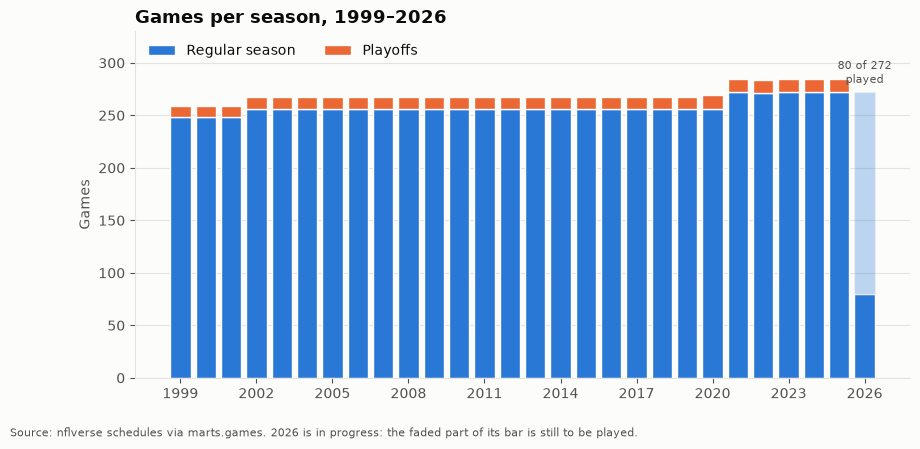

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
gap = dict(edgecolor=plt.rcParams["axes.facecolor"], linewidth=1)  # a thin surface-coloured gap between fills
done = per_season.loc[:LAST_SEASON]
ax.bar(done.index, done["regular"], color=SERIES[0], label="Regular season", **gap)
ax.bar(done.index, done["playoffs"], bottom=done["regular"], color=SERIES[1], label="Playoffs", **gap)

# The season in progress: games played so far solid, the rest of the schedule faded.
for season, row in per_season.loc[LAST_SEASON + 1:].iterrows():
    scheduled = row["regular"] + row["playoffs"]
    ax.bar(season, row["finished"], color=SERIES[0], **gap)
    ax.bar(season, scheduled - row["finished"], bottom=row["finished"], color=SERIES[0], alpha=0.3, **gap)
    ax.annotate(f"{row['finished']} of {scheduled}\nplayed", (season, scheduled), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", color=TEXT_SECONDARY, fontsize=8)

ax.set_title("Games per season, 1999–2026")
ax.set_ylabel("Games")
ax.set_xticks(range(per_season.index.min(), per_season.index.max() + 1, 3))
ax.set_ylim(0, 330)
ax.legend(loc="upper left", ncols=2)
fig.text(0.0, -0.02, "Source: nflverse schedules via marts.games. 2026 is in progress: the faded part of its bar is still to be played.", color=TEXT_SECONDARY, fontsize=8)

save_figure(fig, "games_per_season")
plt.show()

## Done-when check

The counts match the league's format in every complete season, and the figure is saved.

In [4]:
expected_regular = {s: 248 if s <= 2001 else 256 if s <= 2020 else 272 for s in range(1999, LAST_SEASON + 1)}
expected_regular[2022] = 271
expected_playoffs = {s: 11 if s <= 2019 else 13 for s in range(1999, LAST_SEASON + 1)}

complete_seasons = per_season.loc[1999:LAST_SEASON]
assert complete_seasons["regular"].to_dict() == expected_regular
assert complete_seasons["playoffs"].to_dict() == expected_playoffs
assert (complete_seasons["finished"] == complete_seasons["regular"] + complete_seasons["playoffs"]).all()
assert (ROOT / "docs" / "figures" / "games_per_season.png").exists()
print(f"{len(complete_seasons)} complete seasons, {complete_seasons['finished'].sum():,} finished games: all as expected")

27 complete seasons, 7,276 finished games: all as expected
